# №7. Сглаживание с сохранением границ

Цель: сравнить медианный и билатеральный фильтры, проверить влияние параметров
и получить изображение с упрощёнными цветовыми областями.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3, figsize=None):
    rows = (len(images) + cols - 1) // cols
    figsize = figsize or (4 * cols, 3.2 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    fig.tight_layout()
    plt.show()

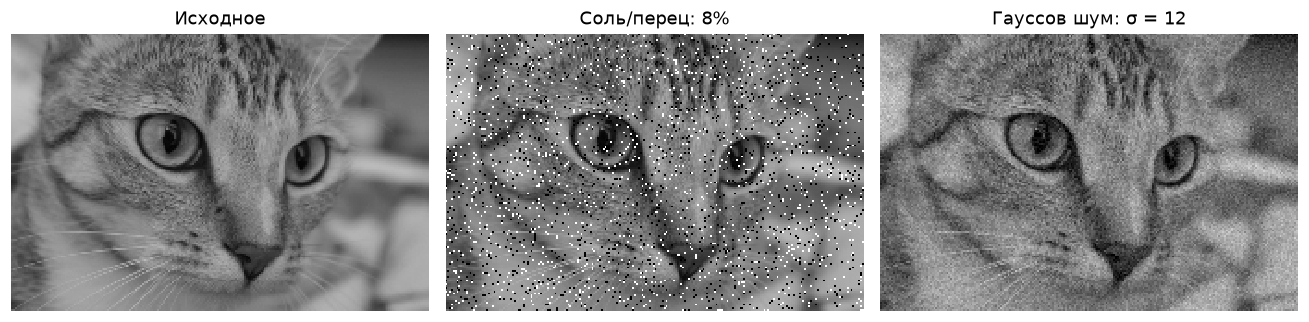

In [3]:
rgb = np.array(Image.open("data/scene.jpg").convert("RGB"))
# Каждая вторая строка и колонка дают компактный пример для экспериментов.
rgb = rgb[::2, ::2]
gray = rgb.astype(float) @ np.array([0.2126, 0.7152, 0.0722])
rng = np.random.default_rng(42)


def salt_pepper(image, fraction, rng):
    result = np.asarray(image, dtype=float).copy()
    h, w = result.shape[:2]
    count = round(fraction * h * w)
    locations = rng.choice(h * w, count, replace=False)
    values = rng.choice([0.0, 255.0], count)
    if result.ndim == 3:
        result.reshape(h * w, -1)[locations] = values[:, None]
    else:
        result.ravel()[locations] = values
    return result


noisy_impulse = salt_pepper(gray, 0.08, rng)
noisy_gaussian = np.clip(gray + rng.normal(0, 12, gray.shape), 0, 255)
show_images([to_uint8(gray), to_uint8(noisy_impulse), to_uint8(noisy_gaussian)],
            ["Исходное", "Соль/перец: 8%", "Гауссов шум: σ = 12"])

## 1. Медианный фильтр

В каждом окне выбирается медиана. Край продолжается зеркально.
Для RGB медиана считается по каждому каналу.

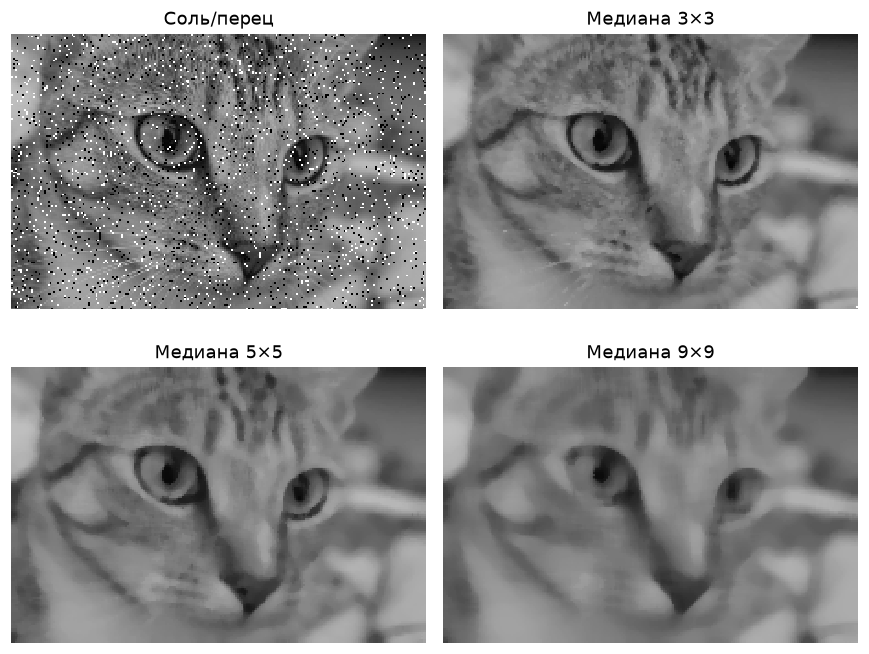

Окно 3: MAE = 4.60
Окно 5: MAE = 6.11
Окно 9: MAE = 8.84


In [4]:
def median_filter(image, size=3):
    source = np.asarray(image, dtype=float)
    radius = size // 2
    padding = ((radius, radius), (radius, radius))
    if source.ndim == 3:
        padding += ((0, 0),)
    padded = np.pad(source, padding, mode="reflect")
    windows = np.lib.stride_tricks.sliding_window_view(padded, (size, size), axis=(0, 1))
    return np.median(windows, axis=(-2, -1))


median_sizes = [3, 5, 9]
median_results = [median_filter(noisy_impulse, size) for size in median_sizes]
show_images([to_uint8(noisy_impulse), *[to_uint8(a) for a in median_results]],
            ["Соль/перец", *[f"Медиана {size}×{size}" for size in median_sizes]], cols=2)
for size, result in zip(median_sizes, median_results):
    print(f"Окно {size}: MAE = {np.mean(np.abs(result - gray)):.2f}")

### Границы и углы

На квадрате измеряем площадь белой области после фильтрации.
Крупное окно округляет углы; прямые участки границы сохраняют резкий переход.

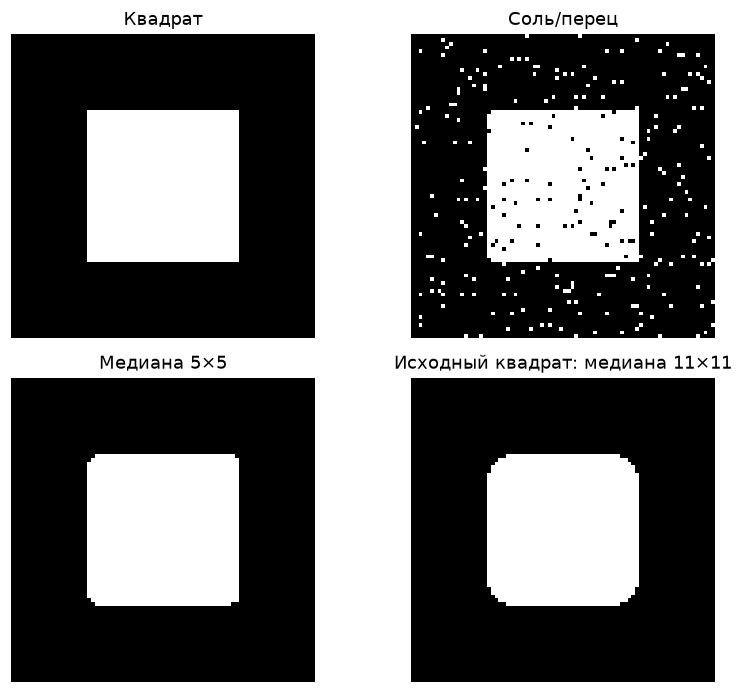

Площадь исходной белой области: 1600
Площадь после медианы 11×11: 1552


In [5]:
square = np.zeros((80, 80))
square[20:60, 20:60] = 255
square_noisy = salt_pepper(square, 0.08, np.random.default_rng(9))
square_median = median_filter(square_noisy, 5)
rounded = median_filter(square, 11)
show_images([square, square_noisy, square_median, rounded],
            ["Квадрат", "Соль/перец", "Медиана 5×5", "Исходный квадрат: медиана 11×11"], cols=2)
print("Площадь исходной белой области:", np.count_nonzero(square == 255))
print("Площадь после медианы 11×11:", np.count_nonzero(rounded == 255))

## 2. Билатеральный фильтр

Вес зависит от расстояния между пикселями и разности яркостей:

$$w_{pq}=\exp\left(-\frac{\|p-q\|^2}{2\sigma_s^2}\right)
\exp\left(-\frac{(I_p-I_q)^2}{2\sigma_r^2}\right),\qquad
I'_p=\frac{\sum_q w_{pq}I_q}{\sum_q w_{pq}}.$$

Знаменатель вычисляется для каждого пикселя. Для RGB используем средний квадрат
разности трёх каналов. Параметр $\sigma_r$ измеряется в уровнях яркости 0–255,
$\sigma_s$ — в пикселях. Размер окна задаёт область расчёта.

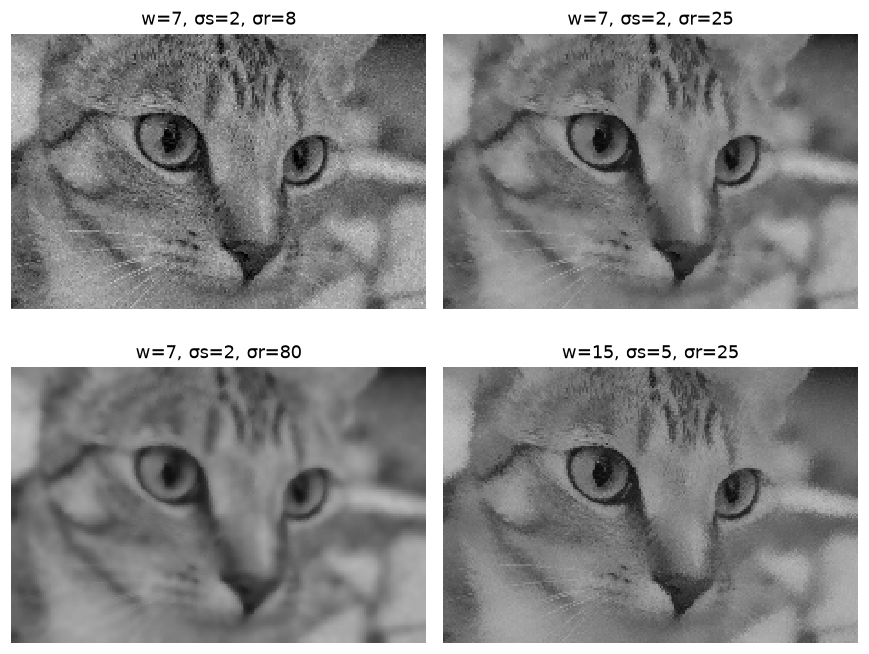

w= 7, σs=2, σr= 8: MAE = 8.23
w= 7, σs=2, σr=25: MAE = 5.58
w= 7, σs=2, σr=80: MAE = 6.83
w=15, σs=5, σr=25: MAE = 6.72


In [6]:
def bilateral_filter(image, size=7, sigma_space=2.0, sigma_range=25.0):
    source = np.asarray(image, dtype=float)
    h, w = source.shape[:2]
    radius = size // 2
    padding = ((radius, radius), (radius, radius))
    if source.ndim == 3:
        padding += ((0, 0),)
    padded = np.pad(source, padding, mode="reflect")
    total = np.zeros_like(source)
    weight_sum = np.zeros((h, w), dtype=float)
    for dy in range(-radius, radius + 1):
        for dx in range(-radius, radius + 1):
            neighbor = padded[radius + dy:radius + dy + h, radius + dx:radius + dx + w]
            difference = (neighbor - source)**2
            if source.ndim == 3:
                difference = difference.mean(axis=2)
            spatial_weight = np.exp(-(dx*dx + dy*dy) / (2 * sigma_space**2))
            weights = spatial_weight * np.exp(-difference / (2 * sigma_range**2))
            total += neighbor * (weights[..., None] if source.ndim == 3 else weights)
            weight_sum += weights
    return total / (weight_sum[..., None] if source.ndim == 3 else weight_sum)


settings = [(7, 2, 8), (7, 2, 25), (7, 2, 80), (15, 5, 25)]
bilateral_results = [bilateral_filter(noisy_gaussian, *setting) for setting in settings]
show_images([to_uint8(a) for a in bilateral_results],
            [f"w={w}, σs={s}, σr={r}" for w, s, r in settings], cols=2)
for (window, space, intensity), result in zip(settings, bilateral_results):
    print(f"w={window:2d}, σs={space}, σr={intensity:2d}: MAE = {np.mean(np.abs(result - gray)):.2f}")

### Сопоставление на одном шуме

На импульсном шуме медиана использует устойчивость центрального элемента упорядоченного окна.
Билатеральный фильтр сохраняет яркие выбросы при малой сигме яркости: их отличие от окружения
даёт окружающим пикселям малый вес.

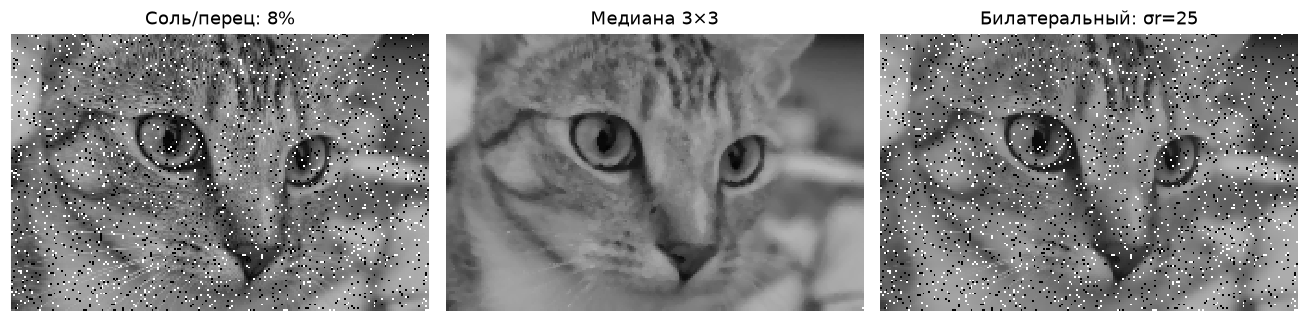

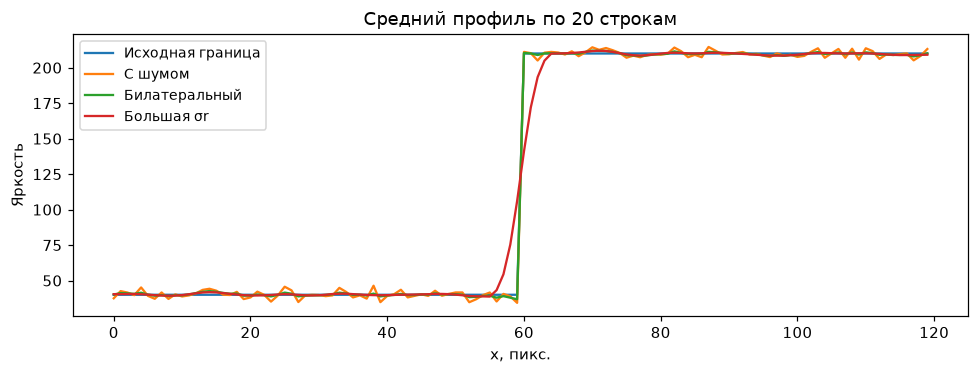

In [7]:
show_images([to_uint8(noisy_impulse), to_uint8(median_filter(noisy_impulse, 3)),
             to_uint8(bilateral_filter(noisy_impulse, 7, 2, 25))],
            ["Соль/перец: 8%", "Медиана 3×3", "Билатеральный: σr=25"])

edge = np.full((80, 120), 40.0)
edge[:, 60:] = 210.0
edge_noisy = np.clip(edge + np.random.default_rng(10).normal(0, 12, edge.shape), 0, 255)
edge_bilateral = bilateral_filter(edge_noisy, 9, 2, 25)
edge_gaussian = bilateral_filter(edge_noisy, 9, 2, 1e6)
fig, ax = plt.subplots(figsize=(9, 3.5))
for result, label in [(edge, "Исходная граница"), (edge_noisy, "С шумом"),
                      (edge_bilateral, "Билатеральный"), (edge_gaussian, "Большая σr")]:
    ax.plot(result[30:50].mean(axis=0), label=label)
ax.set(xlabel="x, пикс.", ylabel="Яркость", title="Средний профиль по 20 строкам")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### Предельные случаи и упрощение цвета

При малой сигме яркости вклад дают пиксели с почти равными значениями.
При большой сигме яркости веса определяются главным образом расстоянием:
получается гауссово сглаживание. Повторные проходы с умеренной сигмой яркости
объединяют мелкую цветовую текстуру в крупные области.

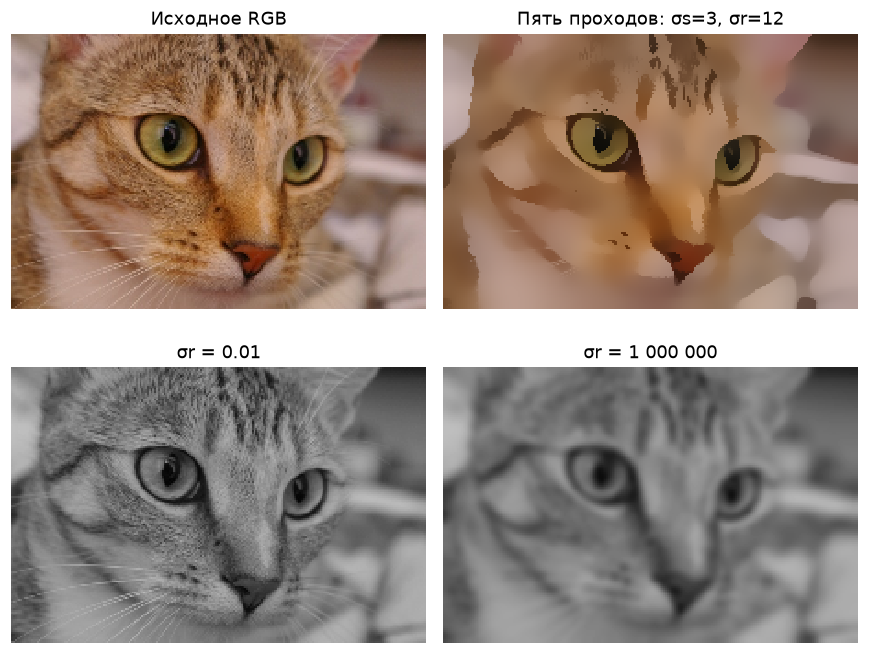

Максимальное изменение при σr = 0.01: 0.00477


In [8]:
near_identity = bilateral_filter(gray, 7, 2, 0.01)
near_gaussian = bilateral_filter(gray, 7, 2, 1e6)
cartoon = rgb.astype(float)
for _ in range(5):
    cartoon = bilateral_filter(cartoon, size=11, sigma_space=3, sigma_range=12)
show_images([rgb, to_uint8(cartoon), to_uint8(near_identity), to_uint8(near_gaussian)],
            ["Исходное RGB", "Пять проходов: σs=3, σr=12",
             "σr = 0.01", "σr = 1 000 000"], cols=2)
print("Максимальное изменение при σr = 0.01:", round(np.max(np.abs(near_identity - gray)), 5))

## Вывод

Медиана эффективно удаляет отдельные импульсы; рост окна округляет углы и сокращает
тонкие элементы. Билатеральный фильтр сглаживает близкие уровни яркости и сохраняет
резкие переходы. Его параметры связывают размер сглаживаемых деталей с допустимым
перепадом яркости. Повторная обработка упрощает цветовую текстуру фотографии.